In [37]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [38]:
df = pd.read_csv("influenza_incidence_data.csv")
print(df.head(5))
print(df.tail(5))
print(df.dtypes)

     week  indicator   inc  inc_low  inc_up  inc100  inc100_low  inc100_up  \
0  202511          3  9923     6285   13561     175         111        239   
1  202511          3  5290     2640    7940      85          43        127   
2  202511          3  9867     6310   13424     118          75        161   
3  202511          3  2323      690    3956      81          24        138   
4  202511          3  3951     2052    5850     113          59        167   

   geo_insee                 geo_name  
0         44                GRAND EST  
1         75       NOUVELLE-AQUITAINE  
2         84     AUVERGNE-RHONE-ALPES  
3         27  BOURGOGNE-FRANCHE-COMTE  
4         53                 BRETAGNE  
         week  indicator  inc  inc_low  inc_up  inc100  inc100_low  inc100_up  \
27386  198444          3  174        0     715       4           0         17   
27387  198444          3    0        0       0       0           0          0   
27388  198444          3    0        0       0  

In [39]:
df=df.rename(columns={"geo_insee":"geo_area"})
df.head(5)

,week,indicator,inc,inc_low,inc_up,inc100,inc100_low,inc100_up,geo_area,geo_name
0,202511,3,9923,6285,13561,175,111,239,44,GRAND EST
1,202511,3,5290,2640,7940,85,43,127,75,NOUVELLE-AQUITAINE
2,202511,3,9867,6310,13424,118,75,161,84,AUVERGNE-RHONE-ALPES
3,202511,3,2323,690,3956,81,24,138,27,BOURGOGNE-FRANCHE-COMTE
4,202511,3,3951,2052,5850,113,59,167,53,BRETAGNE


In [40]:
df.shape

(27391, 10)

In [41]:
duplicate_rows_df = df[df.duplicated()]
print(duplicate_rows_df.shape)

df.count()

df.drop_duplicates(inplace=True)

print(df.isnull().sum())

(0, 10)
week          0
indicator     0
inc           0
inc_low       0
inc_up        0
inc100        0
inc100_low    0
inc100_up     0
geo_area      0
geo_name      0
dtype: int64


In [42]:
df.describe()


,week,indicator,inc,inc_low,inc_up,inc100,inc100_low,inc100_up,geo_area
count,27391.000000,27391.0,27391.000000,27391.000000,27391.000000,27391.000000,27391.000000,27391.000000,27391.000000
mean,200478.210252,3.0,4142.332737,2636.728232,5762.074441,86.261327,53.061042,122.387025,53.307692
std,1165.725504,0.0,9811.835538,8121.860215,11651.191059,194.805555,157.862465,235.879114,27.292043
min,198444.000000,3.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,11.000000
25%,199448.000000,3.0,70.000000,0.000000,250.000000,2.000000,0.000000,8.000000,28.000000
50%,200501.000000,3.0,775.000000,0.000000,1738.000000,19.000000,0.000000,42.000000,52.000000
75%,201507.000000,3.0,3271.500000,1116.000000,5527.500000,72.000000,25.000000,121.000000,76.000000
max,202511.000000,3.0,173156.000000,162468.000000,183844.000000,5103.000000,4733.000000,5473.000000,94.000000


In [43]:
print(df['week'].value_counts().head())

print(df['indicator'].value_counts())

print(df['geo_area'].value_counts())

week
202511    13
199805    13
199807    13
199808    13
199809    13
Name: count, dtype: int64
indicator
3    27391
Name: count, dtype: int64
geo_area
44    2107
75    2107
84    2107
27    2107
53    2107
24    2107
94    2107
11    2107
76    2107
32    2107
28    2107
52    2107
93    2107
Name: count, dtype: int64


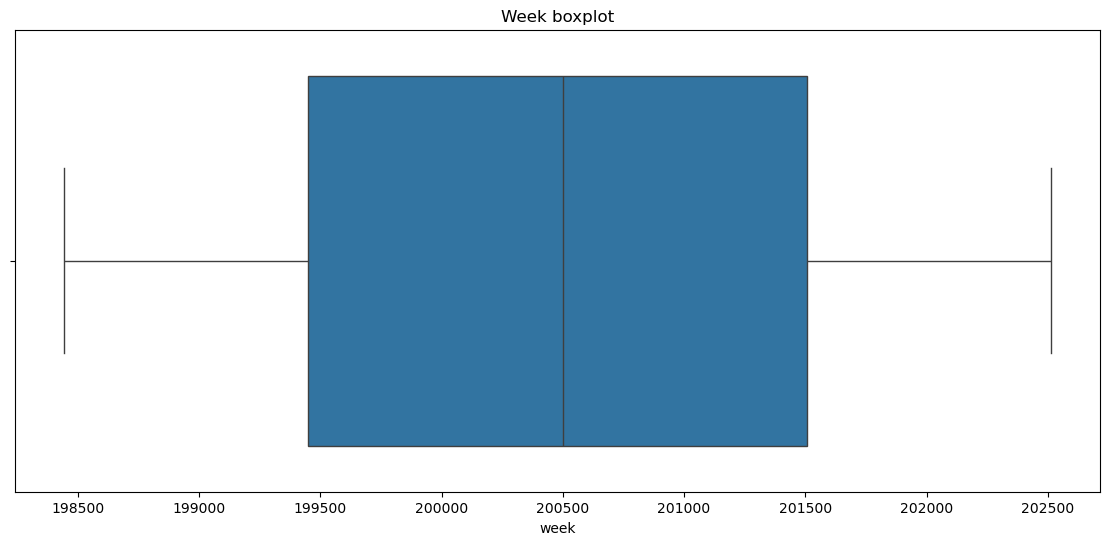

In [44]:
plt.figure(figsize=(14, 6))
sns.boxplot(x='week', data=df)
plt.title("Week boxplot")
plt.show()

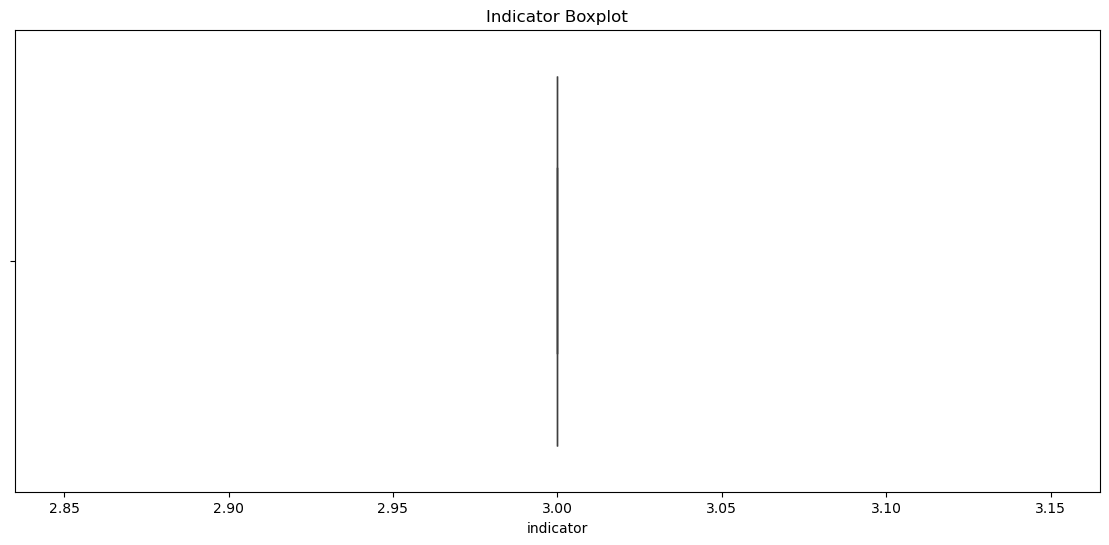

In [45]:
plt.figure(figsize=(14, 6))
sns.boxplot(x='indicator', data=df)
plt.title("Indicator Boxplot")
plt.show()

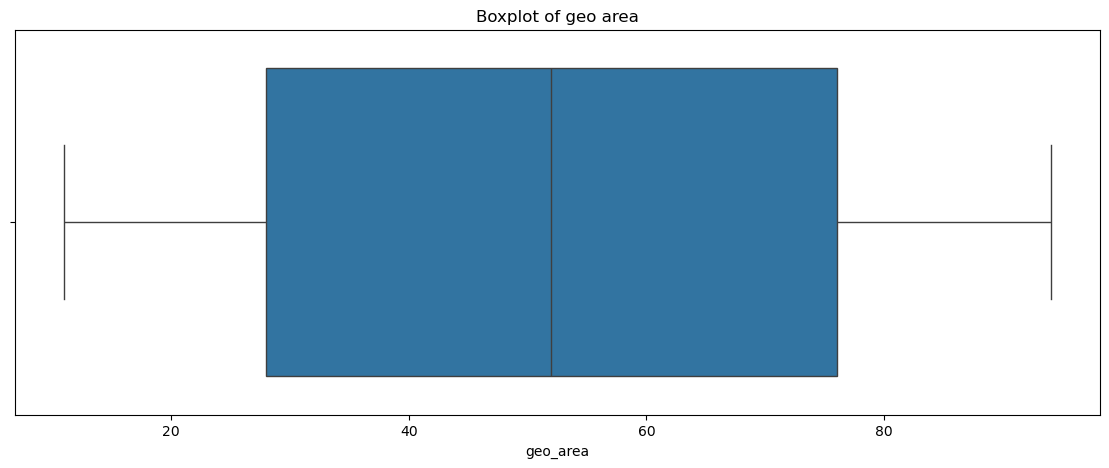

In [46]:
plt.figure(figsize=(14, 5))
sns.boxplot(x='geo_area', data=df)
plt.title("Boxplot of geo area")
plt.show()

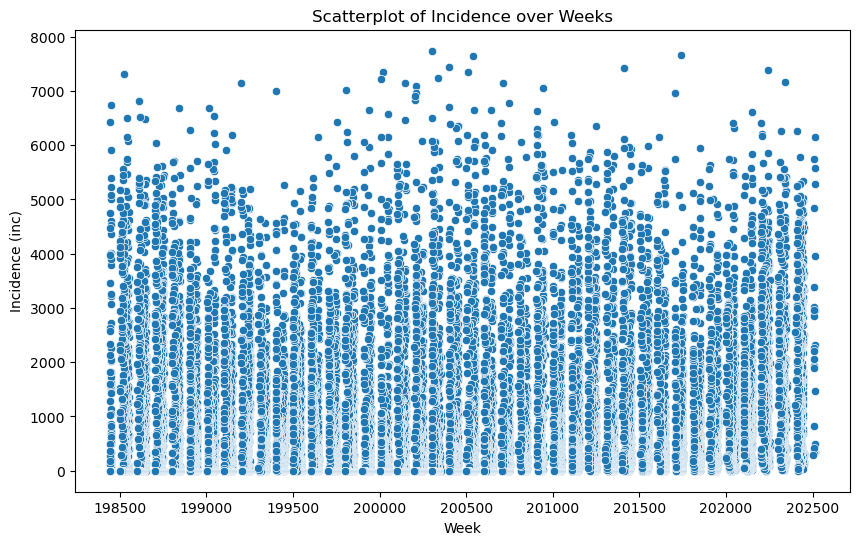

In [52]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='week', y='inc', data=df)
plt.title("Scatterplot of Incidence over Weeks")
plt.xlabel("Week")
plt.ylabel("Incidence (inc)")
plt.show()

In [56]:
mean_values = df[['inc', 'inc_low', 'inc_up', 'inc100', 'inc100_low', 'inc100_up']].mean(numeric_only=True)
print(mean_values)

inc            960.531026
inc_low        217.183149
inc_up        1837.148634
inc100          21.587881
inc100_low       4.631104
inc100_up       41.904619
dtype: float64


In [80]:
max_week = df.loc[df['inc'].idxmax(), 'week']
min_week = df.loc[df['inc'].idxmin(), 'week']

print("Max week", max_week)
print("Min week", min_week)

Max week 200304
Min week 202416


In [90]:
max_geo = df.loc[df['inc'].idxmax(), 'geo_area']
min_geo = df.loc[df['inc'].idxmin(), 'geo_area']

print("geo_area with max inc", max_geo)
print("geo_area with min inc", min_geo)

geo_area with max inc 93
geo_area with min inc 27


In [98]:
correlation = df['inc'].corr(df['geo_area'])
print("Correlation between inc and geo_area:", correlation)

Correlation between inc and geo_area: -0.024451716234857573


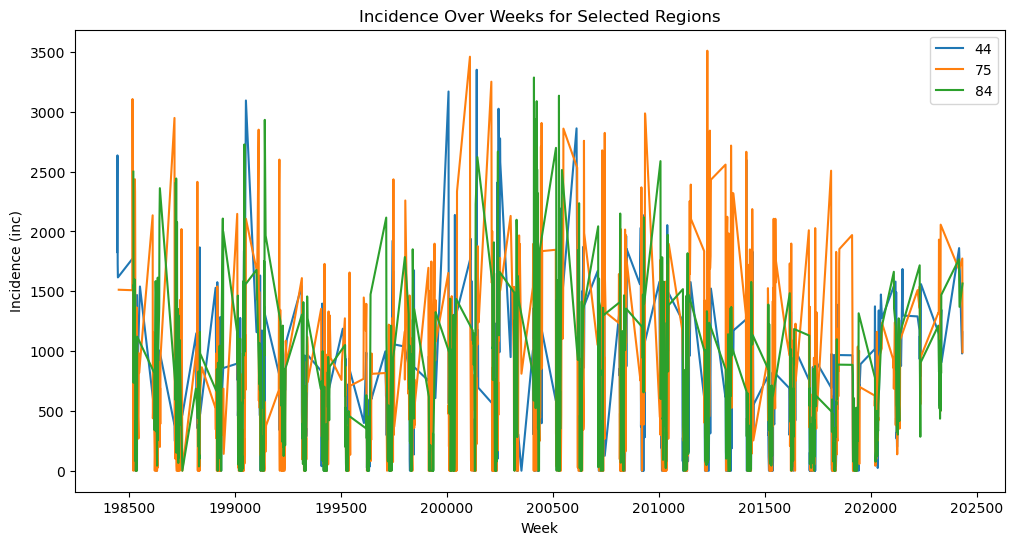

In [160]:
selected_codes =[44, 75, 84]
plt.figure(figsize=(12, 6))
for code in selected_codes:
    subset = df[df['geo_area'] == code]
    plt.plot(subset['week'], subset['inc'], label=str(code))

plt.title("Incidence Over Weeks for Selected Regions")
plt.xlabel("Week")
plt.ylabel("Incidence (inc)")
plt.legend()
plt.show()

In [92]:
df=df.drop(['geo_name'], axis=1)

q1 = df.quantile(0.25)
q3 = df.quantile(0.75)
iqr = q3 - q1
print(iqr)

df = df[~((df < (q1 - 1.5 * iqr)) | (df > (q3 + 1.5 * iqr))).any(axis=1)]

print(df.shape)

week          1983.0
indicator        0.0
inc           1436.0
inc_low         79.0
inc_up        2845.0
inc100          32.0
inc100_low       2.0
inc100_up       63.0
geo_area        48.0
dtype: float64
(16743, 9)


In [ ]:
#monthly averagsx